# MEMAR over all motives from GLORI experiments in HEK293T cells

### Import packages

In [1]:
#Packages needed for the notebook
using CSV 
using Serialization
using Revise 
using LinearAlgebra
using ReverseDiff 
using Random
using PyPlot 
using NaNStatistics 
using Statistics 

### Including Files

In [2]:
function correct_path(splitted_path, String)
    """Function to retrieve files in a given path.
    It takes as input:
        1) splitted path: the current path split by each separator
        2) String: the path to reach the wanted file 
    The function returns:
        1) the correct complete path to reach the file
    """
    S="" #String initialization
    for i in 1:(length(splitted_path)-1)
        #Constructing the path with the correct separator and removing the last term
        S=S*splitted_path[i]*"/" 
    end
    #Final Output
    return S*String 
end

correct_path (generic function with 1 method)

In [3]:
#Including files with the functions
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets

### Datasets

In [4]:
#Importing, training, test and prior datasets
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
test=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Test1_GLORI.bin")) 
prior_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_GLORI.bin")); 

In [5]:
#Saving all the gene labels for the three datasets
gene_train=keys(train);
gene_test=keys(test);
gene_prior=keys(prior_HEK);

### Trained models

In [6]:
#Importing models trained on GLORI HEK293T
M5=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin")) # p(s̄|m)
M6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin")); # p(s̄|m̄)

### Distibution of motives (train-set):

In [7]:
#Computing distribution of m6A and A over transcripts
bin=collect(0:0.001:1);
avarege_window=20
x_met, y_met=avarege_distribution(train, gene_train, avarege_window, bin; label=1)  # d(x(s̄_T)|m)
x_not, y_not=avarege_distribution(train, gene_train, avarege_window, bin, label=0); # d(x(s̄_T)|m̄)

## Test:

In [8]:
#To test genes I only keep those transcripts for which a proxy of the methylation abundancy is knwon
common_genes=intersect(vcat(gene_prior...),vcat(gene_test...)) # T̃ ∩ T 
genes_not=filtering_non_nucelotides(test)
#Removing a gene with non canonical nucleotide letterse
common_genes=setdiff(common_genes, genes_not); # T̃ ∩ T \ T_n 

The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 


### Mapping

In [9]:
#Mapping positions of all coding transcripts into a sequence of 33% 5'-UTR, 33% CDS, 33% 3'-UTR
MAP=mapping_position(test, common_genes);

### Baseline DRACH model

In [10]:
#Creating all test sets over coding transcripts
test_met, ratio_test , gene_test_met , test_not , gene_test_not =crete_set_all(test, (keys(MAP)));

$$p_{BaselineDRACH}(m|\vec{s})=\begin{cases} 1 \ \ \ \ \ if \ \vec{s}\in DRACH \\0 \ \ \ \ \  otherwise \end{cases}$$

In [11]:
#Numerical translation of the previous equation
N_met_a=[null_model(test_met[i]) for i in 1:length(test_met)];
N_not_a=[null_model(test_not[i]) for i in 1:length(test_not)];
#Computing the PCR point and the F1 score
x,y=sum(N_met_a)/length(N_met_a) ,sum(N_met_a)/(sum(N_met_a)+sum(N_not_a)) 
F1=2 .* (y.*x)./(y.+x);
#ROC point 
x_R,y_R=sum(N_not_a)/length(N_not_a) , sum(N_met_a)/length(N_met_a);

### 1. MEMAR-C: Constant prior
$p(1|\vec{s})\propto p(\vec{s}|1)\cdot p_0(1) \ \ \ where \ \ \  p_0(m=1)= \frac{1}{\mathcal{N}_\mathcal{T}}\sum_{i=1}^{\mathcal{N}_\mathcal{T}} \frac{N^{T'_i}_{m^6A}}{N^{T'_i}_{m^6A}+N^{T'_i}_A}=\langle p_0^{T'}(m)\rangle_{T'}$


In [12]:
#Unifor prior definition following the previous equation
Ava=[]
[push!(Ava, train[a].perc_met) for a in gene_train];
Ava=mean(Ava)
constant_prior=deepcopy(test)
[constant_prior[a].perc_met=Ava for a in keys(test)];

In [13]:
score_met_ps,score_not_met_ps=score_ps_ds_pm(M5, M6, test, keys(MAP), constant_prior);

### 2. MEMAR-XC: Modulated distance with constant prior
$p(1|\vec{s})\propto p(\vec{s}|1)\cdot d(x|1) \cdot p_0(1)$

In [14]:
score_met_ps_ds,score_not_met_ps_ds=score_ps_ds_pm(M5, M6,  test, keys(MAP), constant_prior; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not]);

###  3. MEMAR-T: Transcript-dependent Prior
$p(1|\vec{s})\propto p(\vec{s}|1) \cdot p_0^T(1) \ \ \ where \ \ \ p_0^{T_j}(m=1)=\frac{\langle p_0^{T'}(m=1)\rangle_{T'}}{\langle p_0^{\tilde{T}}(m=1)\rangle_{\tilde{T}}}p_0^{\tilde{T}_j}(m=1) $

In [15]:
# Transcript-dependent prior following the above equation
P=[]
[push!(P, prior_HEK[a].perc_met) for a in keys(prior_HEK)]
[prior_HEK[a].perc_met=Ava/mean(P).*prior_HEK[a].perc_met for a in keys(prior_HEK)];

In [16]:
score_met_ps_pm,score_not_met_ps_pm=score_ps_ds_pm(M5, M6, test, keys(MAP), prior_HEK);

### 4. MEMAR-XT: Modulated distant with non-uniform prior
$p(1|\vec{s}) \propto p(\vec{s}|1) d(x|1)\cdot p_0^T(1)$

In [17]:
score_met_ps_ds_pm,score_not_met_ps_ds_pm=score_ps_ds_pm(M5, M6, test, keys(MAP), prior_HEK; verb=true, map=MAP,d_met=[x_met, y_met], d_not=[x_not, y_not]);

#### Statistics

In [25]:
println("Number of Genes: $(length(score_met_ps_ds_pm))")
println("Number of m6A: $(length(vcat(score_met_ps_ds_pm...)))")
println("Number of A: $(length(vcat(score_not_met_ps_ds_pm...)))")

Number of Genes: 1398
Number of m6A: 10783
Number of A: 1709428


### Precision Recall Curve

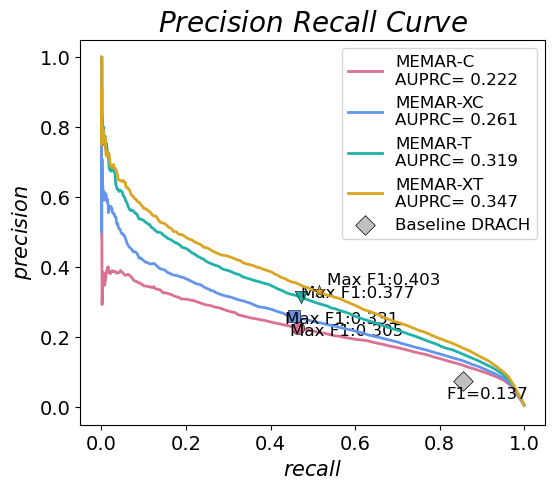

In [18]:
close("all")
figure(figsize=(6, 5))
_,tr1=plot_PR_score(vcat(score_met_ps...), vcat(score_not_met_ps...),  "palevioletred","MEMAR-C"; xx=-0.02, pas=0.005,ls="-", mark="o")
_,tr2=plot_PR_score(vcat(score_met_ps_ds...), vcat(score_not_met_ps_ds...),  "cornflowerblue","MEMAR-XC"; xx=-0.02,pas=0.005, ls="-", mark="s")
_,tr3=plot_PR_score(vcat(score_met_ps_pm...), vcat(score_not_met_ps_pm...),  "lightseagreen","MEMAR-T"; xx=0, pas=0.005,ls="-", mark="v")
_,tr4=plot_PR_score(vcat(score_met_ps_ds_pm...), vcat(score_not_met_ps_ds_pm...),  "goldenrod","MEMAR-XT"; xx=0.02,pas=0.005, ls="-", mark="*")
scatter(x, y, marker="D", color="silver", edgecolor="black", linewidth=0.5, label="Baseline DRACH", s=100)
text(x-.04, y-0.05, "F1=$(round(F1, digits=3))", size=12)
title(L"Precision \ Recall \ Curve ", size=20)
xlabel(L"recall", size=15)
ylabel(L"precision", size=15)
xlim(-0.05, 1.05)
ylim(-0.05, 1.05)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
gcf()

### Receiving Operating Curve

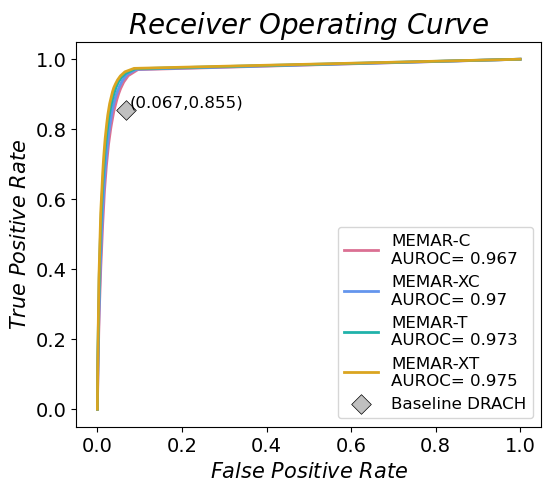

In [19]:
close("all")
close("all")
figure(figsize=(6, 5))
_=plot_ROC_score(vcat(score_met_ps...), vcat(score_not_met_ps...),  "palevioletred","MEMAR-C"; xx=-0.02, pas=0.005,ls="-")
_=plot_ROC_score(vcat(score_met_ps_ds...), vcat(score_not_met_ps_ds...) , "cornflowerblue","MEMAR-XC"; xx=-0.02,pas=0.005, ls="-")
_=plot_ROC_score(vcat(score_met_ps_pm...), vcat(score_not_met_ps_pm...),  "lightseagreen","MEMAR-T"; xx=0, pas=0.005,ls="-")
_=plot_ROC_score(vcat(score_met_ps_ds_pm...), vcat(score_not_met_ps_ds_pm...),  "goldenrod","MEMAR-XT"; xx=0.02,pas=0.005, ls="-")
scatter(x_R, y_R, marker="D", color="silver", edgecolor="black", linewidth=0.5, label="Baseline DRACH", s=100)
text(x_R+0.01, y_R+0.01, "($(round(x_R, digits=3)),$(round(y_R, digits=3)))", size=12)
title(L"Receiver \ Operating \ Curve", size=20)
xlabel(L"False \ Positive \ Rate",  size=15)
ylabel(L"True \ Positive \ Rate", size=15)
xlim(-0.05, 1.05)
ylim(-0.05, 1.05)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
gcf()

### Distance distribution

Computing the predicted distirbution of methylated motifs. Sites with higher or equal probability to the treshold for each MEMAR class are retained and projected into a metagene profile of 1/3 5'-UTR,  1/3 CDS and 1/3 3'-UTR. 

#### MEMAR-C

In [20]:
dist_met_pred_ps=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, Ava/100, test[label].sequence, 8; verbose=false)
    v=findall(x->x>=tr1, S)
    push!(dist_met_pred_ps, MAP[label][v]) 
end

#### MEMAR-XC

In [21]:
dist_met_pred_ps_ds=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, Ava/100, test[label].sequence, 8;  verbose=true, Mapping=MAP, dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=label)
    v=findall(x->x>=tr2, S)
    push!(dist_met_pred_ps_ds, MAP[label][v]) 
end

#### MEMAR-T

In [22]:
dist_met_pred_ps_pm=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, prior_HEK[label].perc_met/100, test[label].sequence, 8; verbose=false)
    v=findall(x->x>=tr3, S)
    push!(dist_met_pred_ps_pm, MAP[label][v]) 
end

#### MEMAR-XT

In [23]:
dist_met_pred_ps_ds_pm=[]
for label in keys(MAP)
    S=score_genome_complete(M5, M6, prior_HEK[label].perc_met/100, test[label].sequence, 8;  verbose=true, Mapping=MAP, dist_met=[x_met, y_met], dist_not=[x_not, y_not], gene=label)
    v=findall(x->x>=tr4, S)
    push!(dist_met_pred_ps_ds_pm, MAP[label][v]) 
end

#### Baseline DRACH model

In [24]:
dist_DRACH=[]
for label in keys(MAP)
    temp=vcat([findall(a, test[label].sequence) for a in DRACH]...)
    pos=[temp[i][3] for i in 1:length(temp)]
    push!(dist_DRACH, MAP[label][sort(pos)]) 
end

In [ ]:
#Computing the same dsitribution form experimental methylated sites
x_met_ref, y_met_ref=avarege_distribution(test, gene_test, avarege_window, bin;label=1);

In [26]:
#Computing the density distirbution in the metagene profile
yy_1, xx_1=hist(vcat(dist_met_pred_ps...), histtype="step" ,bins=bin, density=true, color="palevioletred",alpha=0.4);
yy_2, xx_2=hist(vcat(dist_met_pred_ps_ds...), histtype="step" ,bins=bin, density=true, color="yellowgreen",alpha=0.4);
yy_3, xx_3=hist(vcat(dist_met_pred_ps_pm...), histtype="step" ,bins=bin, density=true, color="lightseagreen",alpha=0.4);
yy_4, xx_4=hist(vcat(dist_met_pred_ps_ds_pm...), histtype="step" ,bins=bin, density=true, color="goldenrod",alpha=0.4);
yy_D, xx_D=hist(vcat(dist_DRACH...), histtype="step" ,bins=bin, density=true, color="lightgrey",alpha=0.4);

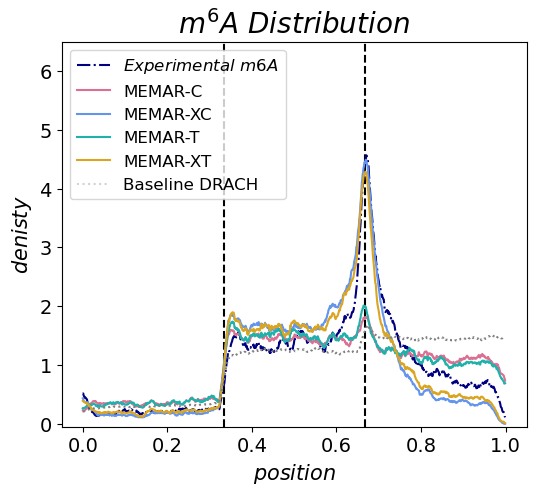

In [27]:
close("all")
figure(figsize=(6, 5))
#plotting each results:
plot(x_met_ref, y_met_ref, color="navy", ls="-.",label=L"Experimental \ m6A ")
plot(xx_1[1:end-1], movmean(yy_1, avarege_window), color="palevioletred")
plot(xx_2[1:end-1], movmean(yy_2, avarege_window), color="cornflowerblue")
plot(xx_3[1:end-1], movmean(yy_3, avarege_window), color="lightseagreen")
plot(xx_4[1:end-1], movmean(yy_4, avarege_window), color="goldenrod")
plot(xx_D[1:end-1], movmean(yy_D, avarege_window), color="grey", ls=":")
axvline(x=1/3, color="black", linestyle="--", zorder=1)
axvline(x=2/3, color="black", linestyle="--", zorder=1)
#Legend
plot(1, 1, label="MEMAR-C",color="palevioletred")
plot(1, 1, label="MEMAR-XC",color="cornflowerblue")
plot(1, 1, label="MEMAR-T",color="lightseagreen")
plot(1, 1, label="MEMAR-XT",color="goldenrod")
plot(1, 1, label="Baseline DRACH ",ls=":",color="lightgrey")
title(L"m^6A \ Distribution", size=20)
ylabel(L"denisty", size=15)
xlabel(L"position", size=15)
ylim(-0.05, 6.5)
xticks(fontsize=14)
yticks(fontsize=14)
legend(fontsize=12)
gcf()